# Quantum Chemistry Part 3

NicDeclic  
2026-10-16

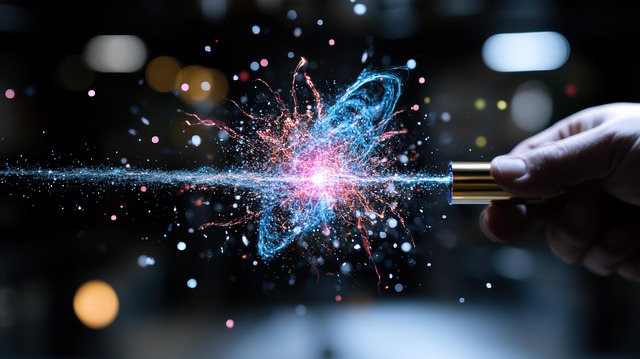

> *“Harmony is not uniformity… it is cacophony learning to dance.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nicdeclic/quantum-molecular-computing/blob/main/posts/quantum-chemistry/index.ipynb)

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

## Solving Molecular Epilepsy

What is needed now is a way to remove the parasitic resonances.

Based on the observation that, generally, the more complex a conjugated
molecule is, the more resonance modes it possesses, it should therefore
be possible to simplify the molecule. That is to say, reduce the
complexity of the bonds in order to keep only the intended resonance
modes.

------------------------------------------------------------------------

## Simplifying the Molecule

If we take the “Letter Envelope” structure and connect the two outputs
of the NOR gates together, we obtain the 4 intended resonances plus the
2 expected parasitic resonances.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Letter Envelope, NOR gates together")

# Add atoms
c2_1 = mol.add_atom(x=-0.8, y=0.5)
c2_2 = mol.add_atom(x=0.8, y=0.5)
c2_3 = mol.add_atom(x=-0.3, y=0)
c2_4 = mol.add_atom(x=0.3, y=0)
c2_5 = mol.add_atom(x=-0.8, y=-0.5)
c2_6 = mol.add_atom(x=0.8, y=-0.5)

# Add bonds
b2_1 = mol.add_bond(c2_1, c2_2, order="single")
b2_2 = mol.add_bond(c2_1, c2_6, order="single", ctrl1=[-2.0, 0.5], ctrl2=[-0.75, -2.5])
b2_3 = mol.add_bond(c2_2, c2_5, order="single", ctrl1=[2.0, 0.5], ctrl2=[0.75, -2.5])
b2_4 = mol.add_bond(c2_1, c2_3, order="single")
b2_5 = mol.add_bond(c2_2, c2_4, order="single")
b2_6 = mol.add_bond(c2_3, c2_4, order="single")
b2_7 = mol.add_bond(c2_3, c2_5, order="single")
b2_8 = mol.add_bond(c2_4, c2_6, order="single")
b2_9 = mol.add_bond(c2_5, c2_6, order="single")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw(margin=0.8) 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>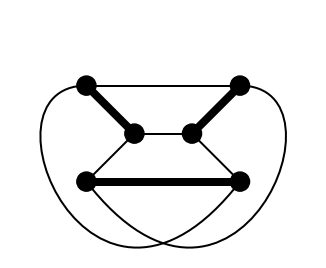</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>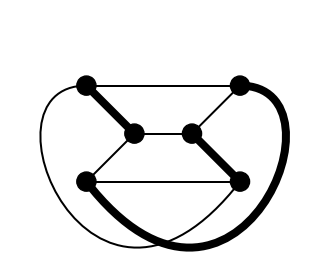</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>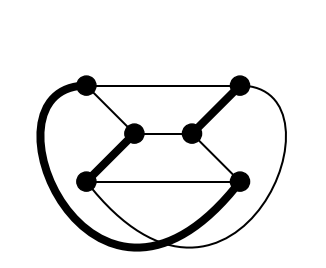</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>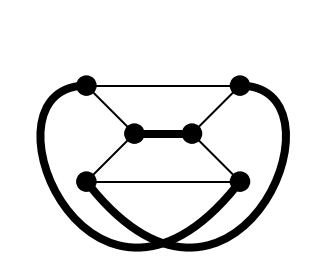</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>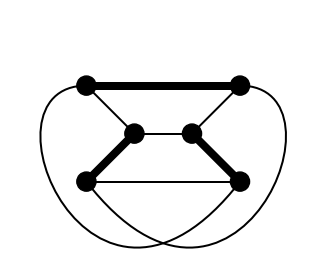</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>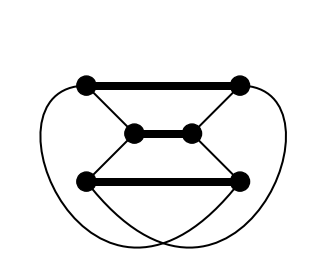</p>
</div></td>
</tr>
</tbody>
</table>

However, if we remove one of the connections, the molecule settles into
a new, stable state without any parasites.

``` python
mol.remove_bond(b2_2)

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw(margin=0.8) 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>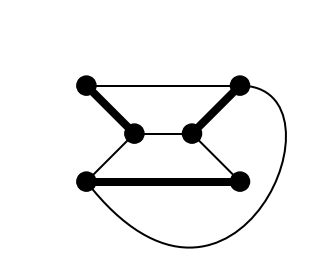</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>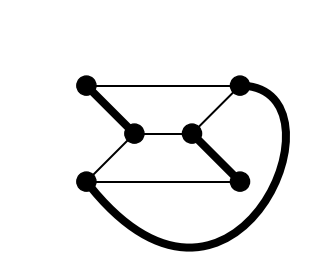</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>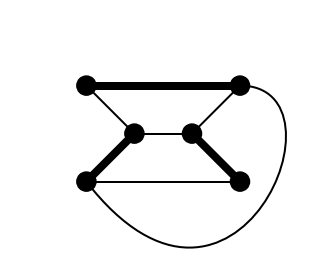</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>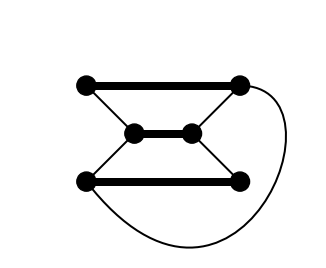</p>
</div></td>
</tr>
</tbody>
</table>

This results in a new structure called the “Barred Eight”. It acts as
the functional equivalent of an AND logic gate.

``` python
#| code-fold: true
#| fig-align: center
#| layout-ncol: 2

# Create a conjugated carbon molecule
mol = CarbonMolecule("Barred Eight")

# Add atoms
c2_1 = mol.add_atom(x=-0.7, y=1.0)
c2_2 = mol.add_atom(x=0.7, y=1.0)
c2_3 = mol.add_atom(x=-0.7, y=0)
c2_4 = mol.add_atom(x=0.7, y=0)
c2_5 = mol.add_atom(x=-0.7, y=-1.0)
c2_6 = mol.add_atom(x=0.7, y=-1.0)

# Add bonds
b2_1 = mol.add_bond(c2_1, c2_2, order="single")
b2_3 = mol.add_bond(c2_2, c2_5, order="single", label="C", label_pos=[0.25, 0.4])
b2_4 = mol.add_bond(c2_1, c2_3, order="single", label="A")
b2_5 = mol.add_bond(c2_2, c2_4, order="single")
b2_6 = mol.add_bond(c2_3, c2_4, order="single")
b2_7 = mol.add_bond(c2_3, c2_5, order="single")
b2_8 = mol.add_bond(c2_4, c2_6, order="single", label="B")
b2_9 = mol.add_bond(c2_5, c2_6, order="single")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>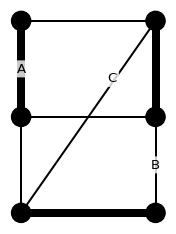</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>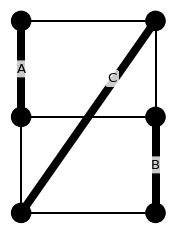</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>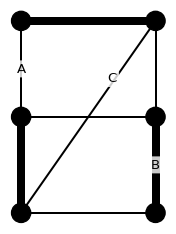</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>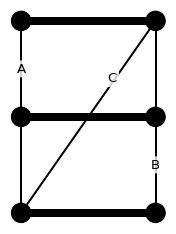</p>
</div></td>
</tr>
</tbody>
</table>

``` python
CarbonMolecule.resonance_table(all_resonances)
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$\begin{array}{|c|c|c|} \hline \mathbf{A}
&amp; \mathbf{B} &amp; \mathbf{C} \\ \hline 1 &amp; 0 &amp; 0 \\ 1 &amp;
1 &amp; 1 \\ 0 &amp; 1 &amp; 0 \\ 0 &amp; 0 &amp; 0 \\ \hline
\end{array}$$</span></p>
</div></td>
</tr>
</tbody>
</table>

Yet, more complex molecules require far more advanced transformations.
It is not always as simple as removing a few bonds.  
Unfortunately, at present, no general algorithm exists to automate this
process. It remains an active area of research.

------------------------------------------------------------------------

## Quantum Couplers

Another approach is to filter the connections directly, since that is
where the parasitic resonances originate.

Ideally, we would insert an intermediate filter molecule along the
interconnect to ensure that both branches always maintain the exact same
logical state.

However, such a purely chemical filter cannot work: because it must
itself be open at both ends to connect into the circuit, it will
inevitably develop the exact same parasitic resonances. We would simply
be reproducing the initial problem.

To break this loop, we must rely on a different physical mechanism:
**quantum and electrostatic induction.**

When two conjugated bonds are brought physically close to one another
without touching, their $\pi$-electron clouds interact across space.
Just like electrical induction in classical physics, the alternating
oscillation of electrons in one bond exerts an electrostatic and quantum
exchange force on the neighbor:  
\* If one bond shifts into a double bond ($\pi$-density), its local
electric field repels or aligns the electron density of the adjacent
bond.  
\* The two lines synchronize their states through the vacuum without
sharing a single physical atom.

This wireless, contact-free bridge is what we call a **Quantum Coupler**
or **Coupler** in short.

The coupling strength follows a strict physical scaling:  
1. **Shorter distance = stronger coupling:** As the spatial gap narrows,
the interaction strength increases drastically.  
2. **More bond pairs = higher efficiency:** Chaining multiple coupled
pairs in parallel reinforces the coherence.

By keeping the distance short enough and using enough parallel bond
pairs, the synchronization efficiency can approach virtually **100%**.

------------------------------------------------------------------------

### Typology of Couplers

Several physical geometries can be engineered:

- **Parallel Coupler:** The simplest design to build. The two branches
  of the dual-rail interconnect are simply routed parallel and brought
  into close physical proximity.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Parallel Coupler")

# Add atoms
c1 = mol.add_atom(x=-2.0, y=0.25, visible=False)
c2 = mol.add_atom(x=-1.5, y=0.0)
c3 = mol.add_atom(x=-1.0, y=0.25)
c4 = mol.add_atom(x=-0.5, y=0.0)
c5 = mol.add_atom(x=0.0, y=0.25)
c6 = mol.add_atom(x=0.5, y=0.0)
c7 = mol.add_atom(x=1.0, y=0.25)
c8 = mol.add_atom(x=1.5, y=0.0)
c9 = mol.add_atom(x=2.0, y=0.25, visible=False)

c10 = mol.add_atom(x=-2.0, y=-0.25, visible=False)
c11 = mol.add_atom(x=-1.5, y=-0.5)
c12 = mol.add_atom(x=-1.0, y=-0.25)
c13 = mol.add_atom(x=-0.5, y=-0.5)
c14 = mol.add_atom(x=0.0, y=-0.25)
c15 = mol.add_atom(x=0.5, y=-0.5)
c16 = mol.add_atom(x=1.0, y=-0.25)
c17 = mol.add_atom(x=1.5, y=-0.5)
c18 = mol.add_atom(x=2.0, y=-0.25, visible=False)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c2, c3, order="single")
b3 = mol.add_bond(c3, c4, order="single")
b4 = mol.add_bond(c4, c5, order="single")
b5 = mol.add_bond(c5, c6, order="single")
b6 = mol.add_bond(c6, c7, order="single")
b7 = mol.add_bond(c7, c8, order="single")
b8 = mol.add_bond(c8, c9, order="single")

b9 = mol.add_bond(c10, c11, order="single")
b10 = mol.add_bond(c11, c12, order="single")
b11 = mol.add_bond(c12, c13, order="single")
b12 = mol.add_bond(c13, c14, order="single")
b13 = mol.add_bond(c14, c15, order="single")
b14 = mol.add_bond(c15, c16, order="single")
b15 = mol.add_bond(c16, c17, order="single")
b16 = mol.add_bond(c17, c18, order="single")

coupler1 = mol.add_coupler(b4, b12)
coupler2 = mol.add_coupler(b5, b13)

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>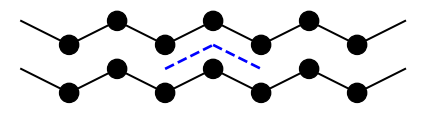</p>
</div></td>
</tr>
</tbody>
</table>

The blue dashed line is here to show that there is a coupling between
bonds.

- **Series Coupler:** The molecular equivalent of the schematic of an
  electrical transformer. Two closed conjugated loops are placed
  side-by-side, transferring logic states purely through mutual
  resonance induction.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Series Coupler")

# Add atoms
c1 = mol.add_atom(x=-2.0, y=0.5)
c2 = mol.add_atom(x=-1.0, y=0.5)
c3 = mol.add_atom(x=-1.0, y=-0.5)
c4 = mol.add_atom(x=-2.0, y=-0.5)

c5 = mol.add_atom(x=-0.5, y=0.5)
c6 = mol.add_atom(x=0.5, y=0.5)
c7 = mol.add_atom(x=0.5, y=-0.5)
c8 = mol.add_atom(x=-0.5, y=-0.5)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c2, c3, order="single")
b3 = mol.add_bond(c3, c4, order="single")
b4 = mol.add_bond(c4, c1, order="single")

b5 = mol.add_bond(c5, c6, order="single")
b6 = mol.add_bond(c6, c7, order="single")
b7 = mol.add_bond(c7, c8, order="single")
b8 = mol.add_bond(c5, c8, order="single")

coupler = mol.add_coupler(b8, b2)

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>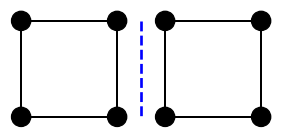</p>
</div></td>
</tr>
</tbody>
</table>

- **$\pi$-Stacking Coupler (Face-to-Face):** Instead of lying in the
  same 2D plane, conjugated rings are stacked directly on top of each
  other (via aromatic $\pi$-$\pi$ stacking). This vertical configuration
  is exceptionally powerful for routing signals out of the plane and
  designing **three-dimensional (3D) molecular circuits**.

![](https://www.chem.ucla.edu/~harding/IGOC/A/aromatic_aromatic_interaction01.png)

Beyond filtering parasites, couplers solve another major engineering
hurdle: **clean fan-out.** They allow a single logic gate to cleanly
broadcast its output to multiple gates without any physical wiring
tangles or parasitic feedback.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Fan-out")

# Add atoms
c1 = mol.add_atom(x=-0.5, y=1.0)
c2 = mol.add_atom(x=0.5, y=1.0)
c3 = mol.add_atom(x=-1.0, y=0.0)
c4 = mol.add_atom(x=1.0, y=0.0)
c5 = mol.add_atom(x=-0.5, y=-1.0)
c6 = mol.add_atom(x=0.5, y=-1.0)

c7 = mol.add_atom(x=-0.5, y=1.4)
c8 = mol.add_atom(x=0.5, y=1.4)
c9 = mol.add_atom(x=-0.5, y=2.5, visible=False)
c10 = mol.add_atom(x=0.5, y=2.5, visible=False)

c11 = mol.add_atom(x=-1.3, y=-0.2)
c12 = mol.add_atom(x=-0.8, y=-1.2)
c13 = mol.add_atom(x=-2.2, y=-1.0, visible=False)
c14 = mol.add_atom(x=-1.7, y=-2.0, visible=False)

c15 = mol.add_atom(x=1.3, y=-0.2)
c16 = mol.add_atom(x=0.8, y=-1.2)
c17 = mol.add_atom(x=2.2, y=-1.0, visible=False)
c18 = mol.add_atom(x=1.7, y=-2.0, visible=False)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c1, c3, order="single")
b3 = mol.add_bond(c2, c4, order="single")
b4 = mol.add_bond(c4, c6, order="single")
b5 = mol.add_bond(c3, c5, order="single")
b6 = mol.add_bond(c5, c6, order="single")

b7 = mol.add_bond(c7, c8, order="single")
b8 = mol.add_bond(c7, c9, order="single")
b9 = mol.add_bond(c8, c10, order="single")

b10 = mol.add_bond(c11, c12, order="single")
b11 = mol.add_bond(c11, c13, order="single")
b12 = mol.add_bond(c12, c14, order="single")

b13 = mol.add_bond(c15, c16, order="single")
b14 = mol.add_bond(c15, c17, order="single")
b15 = mol.add_bond(c16, c18, order="single")

coupler1 = mol.add_coupler(b1, b7)
coupler2 = mol.add_coupler(b5, b10)
coupler3 = mol.add_coupler(b4, b13)

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>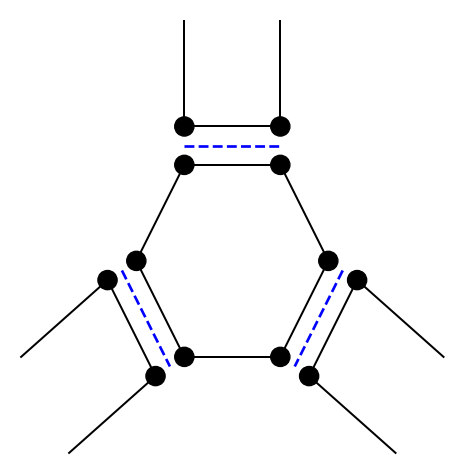</p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

## Molecular Matrix Form

Up to this point, the method for decoding a molecule’s computational
behavior has relied on systematically enumerating all of its individual
resonance structures one by one.

However, there is a much more direct, powerful, and scalable approach:
**computing the global transition matrix algebraically.**

The key strategy is to treat the entire molecule as a directed
mathematical graph and decompose it into elementary topological motifs.

Just as classical electronics relies on wires, transistors, and
resistors, the molecular graph calculus is built from a compact alphabet
of primitive transition operators :

(note: in the following primitives schematics, inputs are on the left
and outputs are on the right)

``` python
mol1 = CarbonMolecule("Identity")
c1_1 = mol1.add_atom(x=-0.5, y=0.0, visible=False)
c1_2 = mol1.add_atom(x=0.5, y=0.0, visible=False)
b1_1 = mol1.add_bond(c1_1, c1_2, order="single")
mol1.draw() 

display_inline("Identity", "=", identity.to_katex(show_labels=True))


mol2 = CarbonMolecule("Negate")
c2_1 = mol2.add_atom(x=-0.5, y=0.0, visible=False)
c2_2 = mol2.add_atom(x=0.0, y=0.5)
c2_3 = mol2.add_atom(x=0.5, y=0.0, visible=False)
b2_1 = mol2.add_bond(c2_1, c2_2, order="single")
b2_2 = mol2.add_bond(c2_2, c2_3, order="single")
mol2.draw() 

display_inline("Negate", "=", negate.to_katex(show_labels=True))


mol3 = CarbonMolecule("Swap")
c3_1 = mol3.add_atom(x=-0.5, y=0.25, visible=False)
c3_2 = mol3.add_atom(x=0.5, y=-0.25, visible=False)
c3_3 = mol3.add_atom(x=-0.5, y=-0.25, visible=False)
c3_4 = mol3.add_atom(x=0.5, y=0.25, visible=False)
b3_1 = mol3.add_bond(c3_1, c3_2, order="single")
b3_2 = mol3.add_bond(c3_3, c3_4, order="single")
mol3.draw() 

display_inline("Swap", "=", swap.to_katex(show_labels=True))


mol4 = CarbonMolecule("Fork")
c4_1 = mol4.add_atom(x=-0.5, y=0.0, visible=False)
c4_2 = mol4.add_atom(x=0.0, y=0.0)
c4_3 = mol4.add_atom(x=0.5, y=0.5, visible=False)
c4_4 = mol4.add_atom(x=0.5, y=-0.5, visible=False)
b4_1 = mol4.add_bond(c4_1, c4_2, order="single")
b4_2 = mol4.add_bond(c4_2, c4_3, order="single")
b4_3 = mol4.add_bond(c4_2, c4_4, order="single")
mol4.draw() 

display_inline("Fork", "=", fork.to_katex(show_labels=True))


mol5 = CarbonMolecule("Merge")
c5_1 = mol5.add_atom(x=-0.5, y=0.5, visible=False)
c5_2 = mol5.add_atom(x=-0.5, y=-0.5, visible=False)
c5_3 = mol5.add_atom(x=0.0, y=0.0)
c5_4 = mol5.add_atom(x=0.5, y=0.0, visible=False)
b5_1 = mol5.add_bond(c5_1, c5_3, order="single")
b5_2 = mol5.add_bond(c5_2, c5_3, order="single")
b5_3 = mol5.add_bond(c5_3, c5_4, order="single")
mol5.draw() 

display_inline("Merge", "=", merge.to_katex(show_labels=True))


mol6 = CarbonMolecule("Open")
c6_1 = mol6.add_atom(x=0.0, y=0.35, visible=False)
c6_2 = mol6.add_atom(x=0.0, y=-0.35, visible=False)
b6_1 = mol6.add_bond(c6_1, c6_2, order="single", ctrl1=[-0.5, 0.5], ctrl2=[-0.5, -0.5])
mol6.draw(margin=0.5)

display_inline("Open", "=", open.to_katex(show_labels=True))


mol7 = CarbonMolecule("Close")
c7_1 = mol7.add_atom(x=0.0, y=0.35, visible=False)
c7_2 = mol7.add_atom(x=0.0, y=-0.35, visible=False)
b7_1 = mol7.add_bond(c7_1, c7_2, order="single", ctrl1=[0.5, 0.5], ctrl2=[0.5, -0.5])
mol7.draw(margin=0.5)

display_inline("Close", "=", close.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>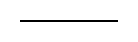</p>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Identity =  \begin{array}{r|cc|}
\text{} &amp; \text{``0''} &amp; \text{``1''} \\  \hline \text{``0''}
&amp; 1 &amp; 0 \\ \text{``1''} &amp; 0 &amp; 1 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>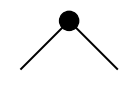</p>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Negate =  \begin{array}{r|cc|} \text{}
&amp; \text{``0''} &amp; \text{``1''} \\  \hline \text{``0''} &amp; 0
&amp; 1 \\ \text{``1''} &amp; 1 &amp; 0 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>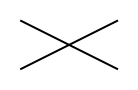</p>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Swap =  \begin{array}{r|cccc|} \text{}
&amp; \text{``00''} &amp; \text{``01''} &amp; \text{``10''} &amp;
\text{``11''} \\  \hline \text{``00''} &amp; 1 &amp; 0 &amp; 0 &amp; 0
\\ \text{``01''} &amp; 0 &amp; 0 &amp; 1 &amp; 0 \\ \text{``10''} &amp;
0 &amp; 1 &amp; 0 &amp; 0 \\ \text{``11''} &amp; 0 &amp; 0 &amp; 0 &amp;
1 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>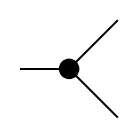</p>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Fork =  \begin{array}{r|cccc|} \text{}
&amp; \text{``00''} &amp; \text{``01''} &amp; \text{``10''} &amp;
\text{``11''} \\  \hline \text{``0''} &amp; 0 &amp; 0.5 &amp; 0.5 &amp;
0 \\ \text{``1''} &amp; 1 &amp; 0 &amp; 0 &amp; 0 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>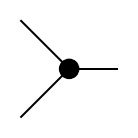</p>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Merge =  \begin{array}{r|cc|} \text{}
&amp; \text{``0''} &amp; \text{``1''} \\  \hline \text{``00''} &amp; 0
&amp; 1 \\ \text{``01''} &amp; 1 &amp; 0 \\ \text{``10''} &amp; 1 &amp;
0 \\ \text{``11''} &amp; 0 &amp; 0 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>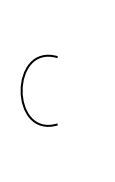</p>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Open =  \begin{array}{r|cccc|} \text{}
&amp; \text{``00''} &amp; \text{``01''} &amp; \text{``10''} &amp;
\text{``11''} \\  \hline ~ &amp; 0.5 &amp; 0 &amp; 0 &amp; 0.5
\\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>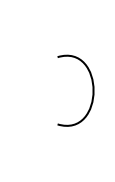</p>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Close =  \begin{array}{r|c|} \text{}
&amp; ~ \\  \hline \text{``00''} &amp; 1 \\ \text{``01''} &amp; 0 \\
\text{``10''} &amp; 0 \\ \text{``11''} &amp; 1 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

Notice the geometric symmetries embedded within these primitives:

- **Self-Dual Motifs:** **Identity**, **Negate**, and **Swap** are their
  own topological duals. Reversing their operational direction leaves
  their matrix representations strictly invariant.
- **Dual Pairs:** **Fork** and **Merge** form a complementary pair: they
  represent the exact same trivalent junction, simply with inputs and
  outputs exchanged. The same directional duality connects **Open** and
  **Close**.

Mathematically, this backward operation is achieved by transposing the
matrix, followed by a row-normalization step to enforce that all
accessible states sum strictly to 1, or 0 for forbidden transitions.

Using standard mathematical notation, transposition is denoted by the
superscript $\mathbf{T}$, while row-normalization is enclosed within
curly braces $\mathbf{\{ \dots \}}$:

For example: $$\text{Fork} = \{\text{Merge}^\mathbf{T}\}$$

$$\text{Merge} = \{\text{Fork}^\mathbf{T}\}$$

Using standard linear algebra—the **Kronecker tensor product
($\otimes$)** for parallel components, and the **matrix dot product
($\cdot$)** for sequential cascade — we can analytically synthesize
complex circuits.

For example, the triangular **XNOR junction** can be calculated directly
by assembling primitive blocks:

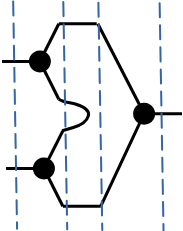

$$\text{Xnor} = \Big\{ (\text{Fork} \otimes \text{Fork}) \cdot (\text{Identity} \otimes \text{Close} \otimes \text{Identity}) \cdot \text{Merge} \Big\}$$

``` python
m = ((fork ^ fork) @ (identity ^ close ^ identity) @ (merge))

display_inline("Xnor", "=", m.normalize().to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ Xnor =  \begin{array}{r|cc|} \text{}
&amp; \text{``0''} &amp; \text{``1''} \\  \hline \text{``00''} &amp; 0
&amp; 1 \\ \text{``01''} &amp; 1 &amp; 0 \\ \text{``10''} &amp; 1 &amp;
0 \\ \text{``11''} &amp; 0 &amp; 1 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

Carrying out this matrix multiplication yields the exact $4 \times 2$
stochastic truth table we previously derived by hand!

This algebraic calculus generalizes seamlessly to larger, closed-form
systems.

- **Couplers** can likewise be expressed in matrix form:

``` python
display_inline("Coupler", "=", coupler_q.to_katex(show_labels=True))
```

<table style="width:50%;">
<colgroup>
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<p><span class="math display">$$ Coupler =  \begin{array}{r|cccc|}
\text{} &amp; \text{``00''} &amp; \text{``01''} &amp; \text{``10''}
&amp; \text{``11''} \\  \hline \text{``00''} &amp; 1 &amp; 0 &amp; 0
&amp; 0 \\ \text{``01''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\
\text{``10''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\ \text{``11''} &amp; 0
&amp; 0 &amp; 0 &amp; 1 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

Rather than acting as spatial routing wires, a Coupler acts as a
**diagonal projector / filter matrix**—algebraically annihilating
incompatible product states across coupled lines and preserving only the
symmetric, synchronized subspace.

------------------------------------------------------------------------

## Finally Success?

**Yes! This time, the foundation holds.**

Every essential building block has now been identified: from fundamental
carbon junctions and resonance states to dual-rail interconnects,
universal NOR logic, and parasitic-filtering couplers. The baseline
theory is established, mathematically coherent, and fully functional!

*“But wait…”* the skeptic might object. *“This is still just theory on
paper, isn’t it? Some concepts seem radically counterintuitive. Where is
the tangible physical prototype?”*

First comes the blueprint, then comes the machine.

Historically, every monumental breakthrough in computing began as quiet
derivations on a notepad. Alan Turing did not begin with silicon
microchips, and quantum computing existed purely on chalkboards decades
before the first qubit was frozen in a lab.

There are still vital, pioneering concepts waiting to be developed — and
that is precisely what the upcoming posts will unpack.

------------------------------------------------------------------------

## 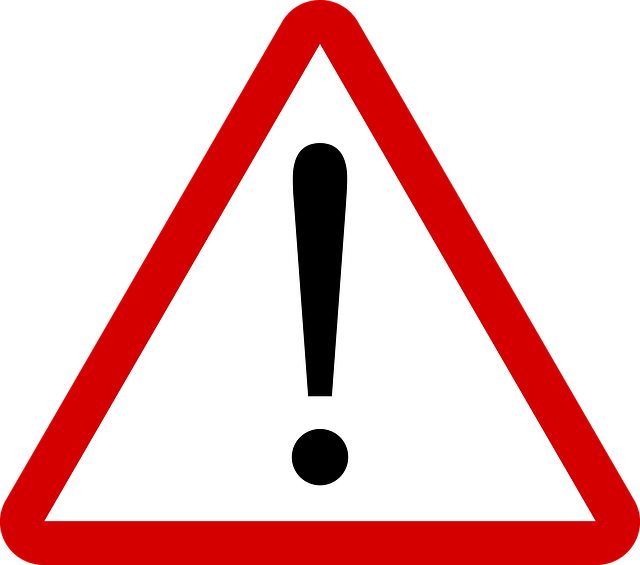 Speculations & Wild Thoughts

- For the Mathematically Inclined: A Bridge to Monoidal Categories &
  ZX-Calculus

The decomposition into Identity, Swap, Fork, and Merge is not an
accident: it directly mirrors the **Symmetric Monoidal Categories
(SMC)** found in modern graphical frameworks like Bob Coecke’s
**ZX-Calculus**.

- **Sequential composition ($\cdot$)** routes resonance across time
  (matrix dot product).
- **Parallel composition ($\otimes$)** spaces lines across space
  (Kronecker product).
- **Duality ($\{\cdot\}^\mathbf{T}$)** provides the “cups and caps” for
  bidirectional, reversible flow.

The radical difference is **ontological**: while the ZX-calculus is an
abstract software tool for quantum compilers, our algebra is
**physically embodied in real matter**.

Here, the nodes are real $sp^2$ carbon atoms, the wires are genuine
$\pi$-bonds, and computation is executed natively as electrons settle
into their ground state.

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“Towards a Physical
Implementation”](../../posts/toward-physical/index.html)**